In [1]:
import warnings
warnings.filterwarnings('ignore')


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

titanic_df = pd.read_csv('./data/train.csv')
titanic_df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [3]:
print('\n ### train 데이터 정보 ###  \n')
print(titanic_df.info())


 ### train 데이터 정보 ###  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


* Null값 처리

In [4]:
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].mean())
titanic_df['Cabin'] = titanic_df['Cabin'].fillna('N')
titanic_df['Embarked'] = titanic_df['Embarked'].fillna('N')
print('데이터 세트 Null 값 갯수 ',titanic_df.isnull().sum())

데이터 세트 Null 값 갯수  PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [5]:
print(' Sex 값 분포 :\n',titanic_df['Sex'].value_counts())
print('\n Cabin 값 분포 :\n',titanic_df['Cabin'].value_counts())
print('\n Embarked 값 분포 :\n',titanic_df['Embarked'].value_counts())

 Sex 값 분포 :
 Sex
male      577
female    314
Name: count, dtype: int64

 Cabin 값 분포 :
 Cabin
N              687
G6               4
C23 C25 C27      4
B96 B98          4
F2               3
              ... 
E17              1
A24              1
C50              1
B42              1
C148             1
Name: count, Length: 148, dtype: int64

 Embarked 값 분포 :
 Embarked
S    644
C    168
Q     77
N      2
Name: count, dtype: int64


In [6]:
# cabin 앞1글자만 자기자신에다 넣기
titanic_df['Cabin'] = titanic_df['Cabin'].str[:1]
print(titanic_df['Cabin'].head(3))

0    N
1    C
2    N
Name: Cabin, dtype: object


* 통계를 통한 주요 피처 검증

In [7]:
# 성별 생존수 : groupby
titanic_df.groupby(['Sex','Survived'])['Survived'].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

<Axes: xlabel='Sex', ylabel='Survived'>

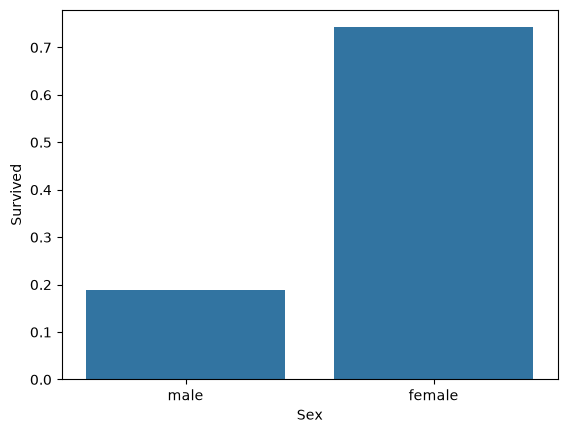

In [8]:
# ci = None : 그래프에 신뢰구간을 나타내지 않음
sns.barplot(x='Sex', y = 'Survived', data=titanic_df, ci = None)

# 결과 : 타이타닉 생존률은 성별에 따라 큰 차이를 보임
# 당시의 사회적 규범이 생존 가능성에 영향을 미쳤음을 알 수 있음
# 단 이 그래프만으로 생존률 차이의 유일한 원인이라고 볼 수 없음 

'\n결과 : \n= 성별 효과 > 계급 효과\n여성은 3등칸이어도 50% 생존했지만, 남성은 **1등칸이어도 37%**에 불과\n성별이 계급보다 더 강력한 생존 결정 요인\n\n= 계급의 영향은 성별에 따라 다르게 작동\n여성: 1등 vs 3등 차이가 극명 (97% → 50%) : 계급 효과 뚜렷\n남성: 등급 간 차이가 상대적으로 작음 (37% → 14%) : 계급이 올라가도 확실한 생존 보장 안 됨\n'

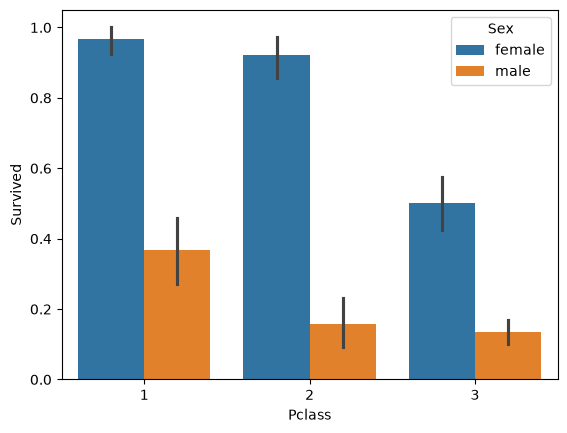

In [9]:
# Pclass별 생존률 시각화와 결과 
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=titanic_df)
'''
결과 : 
= 성별 효과 > 계급 효과
여성은 3등칸이어도 50% 생존했지만, 남성은 **1등칸이어도 37%**에 불과
성별이 계급보다 더 강력한 생존 결정 요인

= 계급의 영향은 성별에 따라 다르게 작동
여성: 1등 vs 3등 차이가 극명 (97% → 50%) : 계급 효과 뚜렷
남성: 등급 간 차이가 상대적으로 작음 (37% → 14%) : 계급이 올라가도 확실한 생존 보장 안 됨
'''

In [10]:
# test code(Python 3.10 이상)
command = "start"

match command:
    case "start":
        print("시작합니다.")
    case "stop":
        print("정지합니다.")
    case "restart":
        print("재시작합니다.")
    case _:
        print("알 수 없는 명령입니다.")

시작합니다.


In [11]:
def get_category(age):
    cat = ''
    if age <= -1: cat = 'Unknown'
    elif age <= 5: cat = 'Baby'
    elif age <= 12: cat = 'Child'
    elif age <= 18: cat = 'Teenager'
    elif age <= 25: cat = 'Student'
    elif age <= 35: cat = 'Young Adult'
    elif age <= 60: cat = 'Adult'
    else : cat = 'Elderly'
    
    return cat

' \n= 결과\nbaby : 남성 생존율 - 63%, 여성 생존율 - 78% (남녀 모두 비교적 생존율이 높음)\nChild : 남성 생존율 -  43% , 여성 생존율 - 28%\nTeenager : 남성 생존율 - 8% , 여성 생존율 - 72%\n\n대부분 연령층에서 여성 생존율이 남성보다 높음\n남성의 경우 Baby와 Child는 상대적으로 다른 연령층에 비해 생존율이 높음\n여성의 대부분은 약 70%~80%이상의 생존율을 보임\n타이타닉 사고 당시 여성과 아이들을 우선 구조했던 경향을 데이터에서 확인해 볼 수 있음\n'

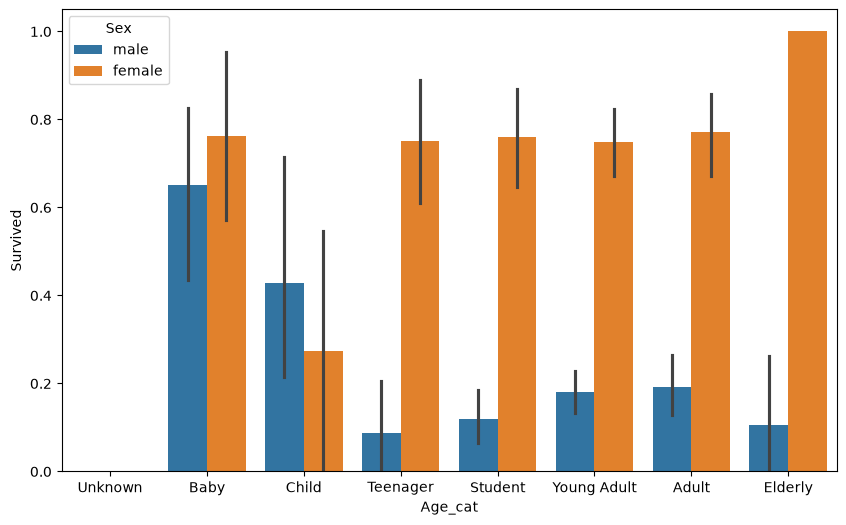

In [12]:
# age 구성 

plt.figure(figsize=(10,6))

group_names = ['Unknown', 'Baby', 'Child', 'Teenager', 'Student', \
    'Young Adult', 'Adult', 'Elderly']

titanic_df['Age_cat'] = titanic_df['Age'].apply(lambda x : get_category(x))
sns.barplot(x='Age_cat', y = 'Survived', hue='Sex', data=titanic_df, order=group_names)
titanic_df.drop('Age_cat', axis=1, inplace=True)
''' 
= 결과
baby : 남성 생존율 - 63%, 여성 생존율 - 78% (남녀 모두 비교적 생존율이 높음)
Child : 남성 생존율 -  43% , 여성 생존율 - 28%
Teenager : 남성 생존율 - 8% , 여성 생존율 - 72%

대부분 연령층에서 여성 생존율이 남성보다 높음
남성의 경우 Baby와 Child는 상대적으로 다른 연령층에 비해 생존율이 높음
여성의 대부분은 약 70%~80%이상의 생존율을 보임
타이타닉 사고 당시 여성과 아이들을 우선 구조했던 경향을 데이터에서 확인해 볼 수 있음
'''


In [13]:
from sklearn import preprocessing

def encode_features(dataDF):
    features = ['Cabin', 'Sex', 'Embarked']
    for feature in features:
        le = preprocessing.LabelEncoder()
        le = le.fit(dataDF[feature].astype(str))
        dataDF[feature] = le.transform(dataDF[feature].astype(str))
        
    return dataDF

titanic_df = encode_features(titanic_df)
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


### titanic 데이터 분석

In [14]:
# NaN 처리 함수
def fillna(df):
    df['Age'] = df['Age'].fillna(df['Age'].mean())
    df['Cabin'] = df['Cabin'].fillna('N')
    df['Embarked'] = df['Embarked'].fillna('N')
    print('데이터 세트 Null 값 갯수 ',df.isnull().sum())
    
    return df
    
# 머신러닝 알고리즘에 불필요한 속성 제거
def drop_features(df):
    df.drop(['PassengerId','Name','Ticket'],axis=1,inplace=True)
    return df

# 레이블 인코딩 수행. 
def format_features(df):
    df['Cabin'] = df['Cabin'].str[:1]
    features = ['Cabin','Sex','Embarked']
    for feature in features:
        le = preprocessing.LabelEncoder()
        le = le.fit(df[feature])
        df[feature] = le.transform(df[feature])
    return df

def transform_features(df):
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [15]:
import pandas as pd

X_titanic_df = pd.read_csv('./data/train.csv')
y_titanic_df = X_titanic_df['Survived']
X_titanic_df= X_titanic_df.drop('Survived',axis=1)

X_titanic_df = transform_features(X_titanic_df)
X_titanic_df.head()

데이터 세트 Null 값 갯수  PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,3,1,22.0,1,0,7.2500,7,3
1,1,0,38.0,1,0,71.2833,2,0
2,3,0,26.0,0,0,7.9250,7,3
3,1,0,35.0,1,0,53.1000,2,3
4,3,1,35.0,0,0,8.0500,7,3


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(X_titanic_df, y_titanic_df, \
                                                  test_size=0.2, random_state=11)

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

dt_clf = DecisionTreeClassifier(random_state=11)
rf_clf = RandomForestClassifier(random_state=11)
lr_clf = LogisticRegression(random_state=11)

# DecisionTreeClassifier 학습/예측/평가
dt_clf.fit(X_train , y_train)
dt_pred = dt_clf.predict(X_test)
print('DecisionTreeClassifier 정확도: {0:.4f}'.format(accuracy_score(y_test, dt_pred)))

# RandomForestClassifier 학습/예측/평가
rf_clf.fit(X_train , y_train)
rf_pred = rf_clf.predict(X_test)
print('RandomForestClassifier 정확도:{0:.4f}'.format(accuracy_score(y_test, rf_pred)))

# LogisticRegression 학습/예측/평가
lr_clf.fit(X_train , y_train)
lr_pred = lr_clf.predict(X_test)
print('LogisticRegression 정확도: {0:.4f}'.format(accuracy_score(y_test, lr_pred)))


DecisionTreeClassifier 정확도: 0.7877
RandomForestClassifier 정확도:0.8547
LogisticRegression 정확도: 0.8492


In [18]:
models = {
    'DecisionTree': DecisionTreeClassifier(random_state=11),
    'RandomForest': RandomForestClassifier(random_state=11),
    'LogisticRegression': LogisticRegression(random_state=11)
}

for name, model in models.items():
    model.fit(X_train, y_train)       # 학습
    pred = model.predict(X_test)      # 예측
    acc = accuracy_score(y_test, pred) # 평가

    print(f'{name} 정확도: {acc:.4f}')

DecisionTree 정확도: 0.7877
RandomForest 정확도: 0.8547
LogisticRegression 정확도: 0.8492


* KFold

In [19]:
from sklearn.model_selection import KFold

def exec_kfold(clf, folds=5):
    kfold = KFold(n_splits=folds)
    scores = []

    # KFold 교차 검증 수행. 
    for iter_count , (train_index, test_index) in enumerate(kfold.split(X_titanic_df)):
        X_train, X_test = X_titanic_df.values[train_index], X_titanic_df.values[test_index]
        y_train, y_test = y_titanic_df.values[train_index], y_titanic_df.values[test_index]

        # Classifier 학습, 예측, 정확도 계산 
        clf.fit(X_train, y_train) 
        predictions = clf.predict(X_test)
        accuracy = accuracy_score(y_test, predictions)
        scores.append(accuracy)
        print("교차 검증 {0} 정확도: {1:.4f}".format(iter_count, accuracy))

    mean_score = np.mean(scores)
    print("평균 정확도: {0:.4f}".format(mean_score)) 
# exec_kfold 호출
exec_kfold(dt_clf , folds=5) 

교차 검증 0 정확도: 0.7542
교차 검증 1 정확도: 0.7809
교차 검증 2 정확도: 0.7865
교차 검증 3 정확도: 0.7697
교차 검증 4 정확도: 0.8202
평균 정확도: 0.7823


In [20]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(dt_clf, X_titanic_df , y_titanic_df , cv=5)
for iter_count,accuracy in enumerate(scores):
    print("교차 검증 {0} 정확도: {1:.4f}".format(iter_count, accuracy))

print("평균 정확도: {0:.4f}".format(np.mean(scores)))

교차 검증 0 정확도: 0.7430
교차 검증 1 정확도: 0.7753
교차 검증 2 정확도: 0.7921
교차 검증 3 정확도: 0.7865
교차 검증 4 정확도: 0.8427
평균 정확도: 0.7879


* HyperParameter + 교차검증 : GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV

# min_samples_split : 데이터가 적은 노드까지 계속 분할할 때 설정된 값보다 작으면 더이상 분할하지 않음(자기자신)
# min_samples_leaf : 분할 후 자식 노드가 너무 적은 데이터만 남을때 분할하지 않음(자식 노드)
parameters = {'max_depth':[2,3,5,10],
            'min_samples_split':[2,3,5], 'min_samples_leaf':[1,5,8]}

dt_clf = DecisionTreeClassifier(random_state=11)
grid_dclf = GridSearchCV(dt_clf , param_grid=parameters , scoring='accuracy' , cv=5)  # refit=True)
grid_dclf.fit(X_train , y_train)

print('GridSearchCV 최적 하이퍼 파라미터 :',grid_dclf.best_params_)
print('GridSearchCV 최고 정확도: {0:.4f}'.format(grid_dclf.best_score_))
best_dclf = grid_dclf.best_estimator_

# GridSearchCV의 최적 하이퍼 파라미터로 학습된 Estimator로 예측 및 평가 수행. 
dpredictions = best_dclf.predict(X_test)
accuracy = accuracy_score(y_test , dpredictions)
precision = precision_score(y_test, dpredictions)
recall = recall_score(y_test, dpredictions)

print('테스트 세트에서의 DecisionTreeClassifier 정확도 : {0:.4f}'.format(accuracy))
print('테스트 세트에서의 DecisionTreeClassifier 정밀도 : {0:.4f}'.format(precision))
print('테스트 세트에서의 DecisionTreeClassifier 재현율 : {0:.4f}'.format(recall))


